# 05 · Members vs. casual riders by time of day

**Who Gets a Bluebike?** · CP 101 final project

Do members and casual riders ride at different times? Members pay for an annual or monthly pass. Casual riders pay per ride or buy a day pass. This notebook compares the hour each group starts its trips, for trips that began at a station inside Boston in 2024.

Run `01_clean_data.ipynb` first. It saves every clean trip, with `hour` and `is_member` columns, to `data/interim/trips/`.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

INTERIM_TRIPS = Path("../data/interim/trips")
CLEAN = Path("../data/clean")

trip_files = sorted(INTERIM_TRIPS.glob("*.parquet"))

# read only the columns we need
trips = pd.concat(
    [pd.read_parquet(p, columns=["start_station_id", "hour", "is_member"]) for p in trip_files],
    ignore_index=True,
)

# keep trips that started at a station inside Boston, to match the rest of the project
stations = pd.read_csv(CLEAN / "stations.csv", dtype={"station_id": str})
boston_ids = stations.loc[stations["in_boston"], "station_id"]
trips = trips[trips["start_station_id"].isin(boston_ids)]

print(f"{len(trips):,} trips started in Boston")
print(f"{len(member_hours):,} by members ({len(member_hours) / len(trips):.0%})")
print(f"{len(casual_hours):,} by casual riders ({len(casual_hours) / len(trips):.0%})")

2,599,793 trips started in Boston
1,765,643 by members (68%)
834,150 by casual riders (32%)


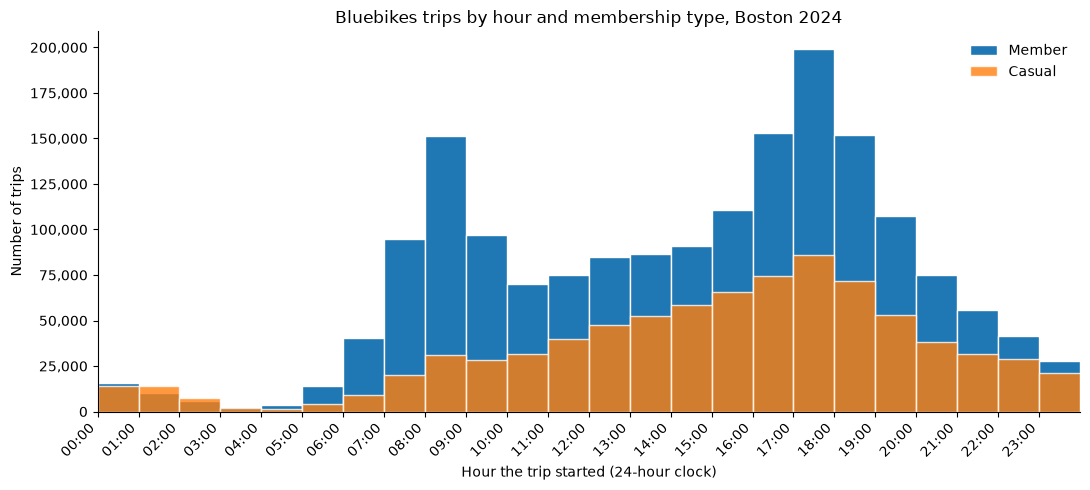

In [8]:
# The same trips as raw counts, stacked, so the bar height is all trips in that hour
# and the orange part shows how many of them were casual riders.
member_hours = trips.loc[trips["is_member"], "hour"]
casual_hours = trips.loc[~trips["is_member"], "hour"]

hour_labels = [str(h).zfill(2) + ":00" for h in range(24)]   # 24-hour clock: "00:00" through "23:00"

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(member_hours, bins=range(25), alpha=1, label="Member", edgecolor="white")
ax.hist(casual_hours, bins=range(25), alpha=0.8, label="Casual", edgecolor="white")
ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels, rotation=45, ha="right")
ax.set_xlim(0, 24)
ax.set_xlabel("Hour the trip started (24-hour clock)")
ax.set_ylabel("Number of trips")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.set_title("Bluebikes trips by hour and membership type, Boston 2024")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()